# Testing TASC when evidence is ambiguous or unavailable

**Question:** Do TASC's timing, engine and topology assumptions provide reliable localization once ambiguity,
refusals and unfavorable comparisons are counted?

Level 4 · Prerequisites: lessons 01–03; read pointwise confusion counts before percentages. · Reading time: 50 minutes.

## Objectives

A factor graph can explain which observations contributed to an inconsistency without proving which source
caused it. We will run Topology-Aware State Coherence, inspect one local evidence factor, construct an
ambiguous flotation syndrome, and deliberately remove observations with and without engine coverage. We
then execute the canonical comparison on held-out cases and recompute paired uncertainty from the full
committed benchmark. The exercise treats unfavorable results and unobservable states as outcomes that must
survive analysis, not obstacles to a preferred product claim.

## Setup

Work in a checkout of OreBridge with the notebook environment active. The computational methods live in
`data-pipeline/pipeline`, so the checkout is required; no released OreBridge PyPI distribution is implied.
Install the exact numerical dependencies once, outside this notebook:

```bash
pip install numpy==2.2.6 scipy==1.18.1 scikit-learn==1.9.1 matplotlib==3.11.2
```

Start the kernel with `OMP_NUM_THREADS=1`, `OPENBLAS_NUM_THREADS=1` and `MKL_NUM_THREADS=1`.
The setup finds the checkout from the working directory without printing a machine path.

In [1]:
# Use the pinned CPU environment and import the implemented scientific methods.
import json
import sys
import importlib.metadata
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython import get_ipython
root = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "VERSION").is_file() and (p / "data-pipeline" / "pipeline").is_dir()
)
sys.path.insert(0, str(root / "data-pipeline"))
get_ipython().run_line_magic("matplotlib", "inline")
from pipeline.model.scenarios import generate, align, channel_specs, conservation_matrix, engine_prior
from pipeline.model.reconciliation import tasc
from pipeline.model.learning import fit_normal
from pipeline.stages.plant_evaluate import calibrate, evaluate_one
from pipeline.stages.analysis import analyze
benchmark = json.loads((root / "data/derived/benchmark.json").read_text(encoding="utf-8"))
committed_analysis = json.loads((root / "data/derived/benchmark-analysis.json").read_text(encoding="utf-8"))
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
for distribution in ["numpy", "scipy", "scikit-learn", "matplotlib"]:
    print(f"{distribution}: {importlib.metadata.version(distribution)}")

numpy: 2.2.6
scipy: 1.18.1
scikit-learn: 1.9.1
matplotlib: 3.11.2


## Data

Owner: OreBridge, [public MIT repository](https://github.com/fsantibanezleal/CAOS_OreBridge); authored
synthetic class. `data/derived/benchmark.json` contains 768 scenarios × 8 methods and the actual pointwise
confusion counts. `data/derived/benchmark-analysis.json` records the companion analysis protocol. Test seeds
are 1000–1015, severities 0.5, 1, 2 and 4, with disjoint fitting and two calibration groups. The local cases
below are regenerated by the same implemented scenario generator. No site geometry or actual plant
measurements have been supplied; independent upstream engine examples remain separate reference cases.

## Method

TASC combines admitted observations $y$ and compatible engine pseudo-observations $m$. Its objective is
$\sum_{j\in V}\rho_\delta((x_j-y_j)/\sigma_j)+
\sum_{j\in E}\rho_\delta((x_j-m_j)/\tau_j)$, subject to $Ax=b$.
Huber's loss supplies bounded large-residual influence ([Huber](https://doi.org/10.1214/aoms/1177703732)); conservation supplies equality
factors ([mineral reconciliation](https://doi.org/10.1016/j.mineng.2018.04.023)). Neither ingredient by itself establishes causal fault identity.
OreBridge proposes this particular combination with time alignment, validity handling and local provenance.
Existing learned sensor relationships, including [GDN](https://arxiv.org/abs/2106.06947), remain relevant prior work.

The engine prior here is a fixed dry-solids ratio anchored to a reference operating point and driven only
by observed upstream feed. It receives no clean truth. Water channels have no engine coverage. We use the
declared four-percent nominal engine uncertainty from the benchmark, not a fitted confidence interval.
Begin with a severity-four feed bias, align observations, and ask the single-row implementation for its
estimate and original-observation factor innovations. A factor's innovation is $A_i y-b_i$, normalized by
$\sqrt{\sum_j(A_{ij}\sigma_j)^2}$ when every contributing observation is valid.

In [2]:
# Fuse only covered engineering quantities and retain the factor's original observations.
specs = channel_specs()
sigma = np.array([s["sigma"] for s in specs])
nominal = np.array([s["nominal"] for s in specs])
matrix = conservation_matrix()
case = generate("bias", seed=1000, severity=4)
aligned_values = align(case.observed)
aligned_valid = align(case.valid)
prior, coverage = engine_prior(aligned_values)
engine_sigma = np.maximum(0.04 * nominal, 0.4)
fused = tasc(aligned_values[90], sigma, matrix, np.zeros(11), valid=aligned_valid[90],
             engine=prior[90], engine_sigma=engine_sigma, engine_valid=coverage[90])
factor = fused["evidence"][4]
print(f"Flotation factor innovation: {factor['innovation']:.6f} t/h; normalized: {factor['normalized']:.6f} σ")
print(f"Largest estimated balance residual: {np.max(np.abs(fused['balance_residual'])):.12f}")
print("Contributing channels:", [specs[j]["id"] for j in factor["channels"]])

Flotation factor innovation: 104.802367 t/h; normalized: 10.424566 σ
Largest estimated balance residual: 0.000000000000
Contributing channels: ['FL1.feed', 'FL1.concentrate', 'FL1.tailings']


A large normalized innovation points to a small set of inconsistent readings. To see the limitation,
return to the three flotation channels. An extra ten t/h at feed and a missing ten t/h at tailings produce
the same scalar syndrome. Both hypotheses are compatible with a single measured balance residual, despite
implicating different instruments. Run the same TASC solver on the small observation vector and print the
constraint rank. A unique numerical optimum does not remove the two-dimensional physical ambiguity.

In [3]:
# Demonstrate indistinguishable fault syndromes with actual channel units and constraints.
columns = [5, 6, 7]
flotation_matrix = matrix[4:5, columns]
candidate_faults = np.array([[10.0, 0.0, 0.0], [0.0, 0.0, -10.0]])
syndromes = candidate_faults @ flotation_matrix.T
ambiguous = nominal[columns] + candidate_faults[0]
small_result = tasc(ambiguous, sigma[columns], flotation_matrix, [0.0])
print("Two candidate fault syndromes:", syndromes.ravel(), "t/h")
print(f"Flotation constraint rank: {np.linalg.matrix_rank(flotation_matrix)}; unconstrained directions: 2")
print("TASC adjustments without an engine prior:", np.round(small_result["state"] - ambiguous, 6), "t/h")

Two candidate fault syndromes: [10. 10.] t/h
Flotation constraint rank: 1; unconstrained directions: 2
TASC adjustments without an engine prior: [-5.129072e+00  3.423000e-03  4.867505e+00] t/h


Next remove one dry-solids observation that does have a compatible engine row. The single-row method may
return a model-assisted state, but its score for that missing observation must remain unavailable and any
factor requiring that observation must report that it was not observed. The validity mask in these
synthetic scenarios emulates rejection by an ingestion contract; it is not a learned detector of stale
clocks, wrong units or swapped tags.

In [4]:
# Keep a missing observed value invalid even when the engine permits an estimated state.
missing_dry = aligned_values[90].copy()
dry_valid = aligned_valid[90].copy()
missing_dry[5] = np.nan
dry_valid[5] = False
dry_result = tasc(missing_dry, sigma, matrix, np.zeros(11), valid=dry_valid, engine=prior[90],
                  engine_sigma=engine_sigma, engine_valid=coverage[90])
print("Dry-solids state status:", "estimated" if dry_result["state_status"] == "estimated" else "refused")
print("Missing observation score:", dry_result["score"][5])
print("Flotation factor observed:", "yes" if dry_result["evidence"][4]["observed"] else "no")
innovation = dry_result["evidence"][4]["innovation"]
print("Unavailable factor innovation:", "null" if innovation is None else innovation)

Dry-solids state status: estimated
Missing observation score: nan
Flotation factor observed: no
Unavailable factor innovation: null


Repeat the removal for tank inflow, which has no dry-solids engine coverage. The implemented admission
rule requires every coordinate to have an observation or an engine row; it conservatively returns
unobservable otherwise. Some networks could identify a missing coordinate from conservation alone, but
this routine does not perform that more general observability analysis. We report the actual refusal
rather than describing an imagined recovery capability.

In [5]:
# Exercise the conservative refusal when neither measurement nor compatible engine covers a coordinate.
missing_water = aligned_values[90].copy()
water_valid = aligned_valid[90].copy()
missing_water[14] = np.nan
water_valid[14] = False
water_result = tasc(missing_water, sigma, matrix, np.zeros(11), valid=water_valid, engine=prior[90],
                    engine_sigma=engine_sigma, engine_valid=coverage[90])
print("Water state status:", "unobservable" if water_result["state"] is None else "estimated")
print("Invalid channel indices:", water_result["invalid"])
coverage_text = ["yes" if good else "no" for good in coverage[90, 12:]]
print("Engine coverage of water channels:", coverage_text)

Water state status: unobservable
Invalid channel indices: [14]
Engine coverage of water channels: ['no', 'no', 'no', 'no']


Inspect the difference between original readings and state estimates for the selected biased row. The
plot below preserves the missing observation as a gap; the engine-assisted estimate is a separate marker.
All plotted channels are dry-solids quantities so the common vertical unit is meaningful. The invalidity
is deliberately induced after scenario generation to test the method's boundary, not inferred from a
detector trained on these readings.

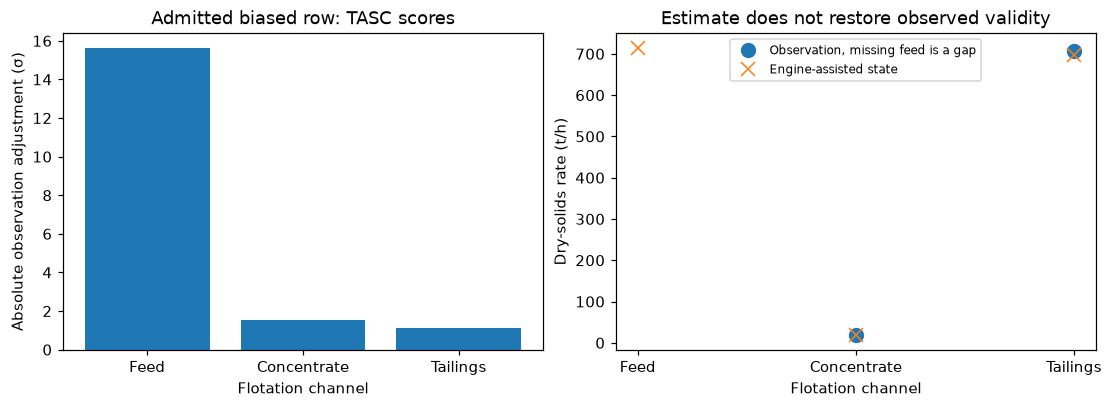

In [6]:
# Keep raw observations and inferred states visibly separate at the missing-data boundary.
positions = np.arange(3)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
axes[0].bar(positions, fused["score"][columns])
axes[0].set(title="Admitted biased row: TASC scores", ylabel="Absolute observation adjustment (σ)")
axes[1].plot(positions, missing_dry[columns], "o", markersize=9, label="Observation, missing feed is a gap")
axes[1].plot(positions, dry_result["state"][columns], "x", markersize=9, label="Engine-assisted state")
axes[1].set(title="Estimate does not restore observed validity", ylabel="Dry-solids rate (t/h)")
axes[1].legend(fontsize=8)
for axis in axes:
    axis.set_xticks(positions, ["Feed", "Concentrate", "Tailings"])
    axis.set_xlabel("Flotation channel")
plt.show()

The first panel localizes the large correction to a small part of the flotation balance, yet the earlier
equal-syndrome example prevents treating that localization as proof of cause. In the second panel there
is no observed feed marker: the model-assisted state did not manufacture an instrument reading. Its
associated factor innovation stayed null. The same implementation refused the uncovered water coordinate,
so a display must preserve both the gap and the explicit state status rather than coloring either case healthy.

## Comparison

The canonical benchmark has a deliberately stricter batch policy than the single-row example. It masks
rejected readings before carrying the last finite value for numeric model input, never for observed-state display.
A rejected finite reading therefore cannot become new model history. If any required
observation in a constrained row is invalid, all sixteen numerical scores of that row are made unavailable.
Quality rejection is scored separately. Forecast inputs remain finite after the declared carry-forward
preparation, while the invalid observation itself is excluded from numerical comparison. These different
score-support policies affect denominators and must accompany aggregate precision and false-alert rates.

The recovery perturbation satisfies $A\Delta\approx0$ at simultaneous raw time. Unequal channel shifts
move its onset and end to different aligned times, so an aligned row can straddle an event boundary.
Alignment can then introduce nonzero factor residuals even though the simultaneous perturbation was balanced.
The canonical recovery case therefore tests fixed-prior compatibility together with these transient
alignment effects. Its recall cannot isolate prior compatibility alone. The same-clock null-space
calculation in lesson 03 keeps its original interpretation.

Fit the normal predictor again and calibrate the actual canonical methods with their disjoint seeds. This
calls the same maintained histogram estimator described in its [official documentation](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingRegressor.html),
without loading the committed checkpoint. We will not refit or retune it after examining test results.

In [7]:
# Recreate the normal fit and the canonical fixed-threshold protocol before held-out evaluation.
bundle = fit_normal()
thresholds = calibrate(bundle)
print(f"Training rows: {bundle['normal_training_rows']}; "
      f"forecast calibration rows: {bundle['calibration_rows']}")
print("Disjoint seed groups:", bundle["train_seeds"], bundle["calibration_seeds"], list(range(300, 308)))

Training rows: 1568; forecast calibration rows: 784
Disjoint seed groups: [100, 101, 102, 103, 104, 105, 106, 107] [200, 201, 202, 203] [300, 301, 302, 303, 304, 305, 306, 307]


Run the complete eight-method pipeline on a recovery-relation shift, the unmodeled-delay negative control
and a missing-water case. The delay family injects no sensor fault, so every process alarm there is false.
The missing family tests declared input rejection rather than a learned ability to discover missingness.
Keep the actual null recall and unscorable counts. Method names remain the pipeline's stable identifiers
in the result object, while the printed descriptions explain their meaning.

In [8]:
# Exercise the actual ablations and retain refusal support alongside detection metrics.
method_labels = {"threshold": "Fixed threshold", "wls": "WLS", "robust-aligned": "Aligned Huber",
                 "forecast": "HGB", "tasc": "TASC", "tasc-no-timing": "TASC without timing",
                 "tasc-no-engine": "TASC without engine", "tasc-no-topology": "TASC without topology"}
family_labels = {"engine": "Recovery shift", "delay": "Delay control", "missing": "Missing water"}
selected_rows = {}
for family in ["engine", "delay", "missing"]:
    rows, outputs, _ = evaluate_one(generate(family, seed=1000, severity=2), bundle, thresholds)
    selected_rows[family] = {row["method"]: row for row in rows}
for family, methods in selected_rows.items():
    for method in ["robust-aligned", "forecast", "tasc", "tasc-no-topology"]:
        row = methods[method]
        recall = row["numeric"]["recall"]
        recall_text = "null (undefined)" if recall is None else f"{recall:.6f}"
        print(f"{family_labels[family]}/{method_labels[method]}: recall={recall_text}; "
              f"false alarms={row['numeric']['fp']}; "
              f"unscorable entries={row['unscorable_points']}")

Recovery shift/Aligned Huber: recall=0.023333; false alarms=16; unscorable entries=0
Recovery shift/HGB: recall=0.970000; false alarms=19; unscorable entries=0
Recovery shift/TASC: recall=0.036667; false alarms=15; unscorable entries=0
Recovery shift/TASC without topology: recall=0.500000; false alarms=7; unscorable entries=0
Delay control/Aligned Huber: recall=null (undefined); false alarms=56; unscorable entries=0
Delay control/HGB: recall=null (undefined); false alarms=31; unscorable entries=0
Delay control/TASC: recall=null (undefined); false alarms=55; unscorable entries=0
Delay control/TASC without topology: recall=null (undefined); false alarms=67; unscorable entries=0
Missing water/Aligned Huber: recall=null (undefined); false alarms=9; unscorable entries=800
Missing water/HGB: recall=null (undefined); false alarms=24; unscorable entries=50
Missing water/TASC: recall=null (undefined); false alarms=9; unscorable entries=800
Missing water/TASC without topology: recall=null (undef

## Evidence

The local recovery-shift case shows TASC's low recall in the combined prior-compatibility and alignment
experiment; the delay control shows a cost of misspecified transport; the missing case counts an explicit abstention.
None is selected as a
representative average. For breadth, use every count in the committed full benchmark and rerun its
implemented analysis. This does not rerun all 768 simulations inside the notebook: the frozen matrix is
the input to a new paired analysis, while the cells above genuinely ran the scientific estimators.

The analysis resamples sixteen held-out seed blocks 5000 times with random seed 414. All families, severities
and channel-time dependence within a seed remain together, so millions of correlated points are not treated
as independent trials. Its intervals describe this synthetic experiment; they cannot be read as uncertainty
about field performance. The helper restores null family ratios when a denominator is zero, although it
uses zeros internally during bootstrap arithmetic. Inspect that boundary explicitly.

In [9]:
# Rerun paired seed-block uncertainty from all committed case counts and preserve null ratios.
analysis = analyze(benchmark, replicates=5000)
print(f"Method/scenario cells: {len(benchmark['rows'])}; "
      f"held-out seeds: {len(benchmark['protocol']['test_seeds'])}")
print(f"Paired bootstrap replicates: {analysis['protocol']['replicates']}")
delay_family = next(r for r in analysis["by_family"] if r["family"] == "delay" and r["method"] == "tasc")
delay_recall = delay_family["ratios"][1]
print("Delay-control TASC recall, undefined:", "null" if delay_recall is None else delay_recall)
print("Delay-control TASC false alarms in the full matrix:", delay_family["counts"][1])

Method/scenario cells: 6144; held-out seeds: 16
Paired bootstrap replicates: 5000
Delay-control TASC recall, undefined: null
Delay-control TASC false alarms in the full matrix: 3532


The full matrix contains different numerical score supports, so recompute aggregate counts and retain the
refusal burden next to recall and false-positive rate. The source-quality-valid analysis removes all five
quality-rejection families for a common-support comparison. Its recall ordering still matters even when
invalid data are absent. Do not present a lower pooled false-positive rate as an unqualified win if the
corresponding method declined more numerical entries.

In [10]:
# Recompute aggregate evidence and display the different abstention denominators.
method_order = [r["method"] for r in benchmark["aggregate"]]
aggregate = {}
for method in method_order:
    subset = [r for r in benchmark["rows"] if r["method"] == method]
    counts = {key: sum(r["numeric"][key] for r in subset) for key in ["tp", "fp", "fn", "tn"]}
    counts["recall"] = counts["tp"] / (counts["tp"] + counts["fn"])
    counts["fpr"] = counts["fp"] / (counts["fp"] + counts["tn"])
    counts["unscorable"] = sum(r["unscorable_points"] for r in subset)
    aggregate[method] = counts
    print(f"{method_labels[method]}: recall={100 * counts['recall']:.6f}%; "
          f"false-positive rate={100 * counts['fpr']:.6f}%; "
          f"unscorable={counts['unscorable']}")
matched = {r["method"]: r for r in analysis["matched_source_valid"]}
common_methods = ["tasc", "forecast", "tasc-no-topology"]
common_recalls = {method_labels[m]: round(matched[m]["recall"], 6) for m in common_methods}
print("Recall on the common source-valid subset:", common_recalls)

Fixed threshold: recall=30.650000%; false-positive rate=0.000000%; unscorable=16000
WLS: recall=14.809375%; false-positive rate=0.961125%; unscorable=256000
Aligned Huber: recall=33.621875%; false-positive rate=0.896452%; unscorable=256000
HGB: recall=83.993750%; false-positive rate=1.591022%; unscorable=16000
TASC: recall=34.190625%; false-positive rate=0.888152%; unscorable=256000
TASC without timing: recall=23.475000%; false-positive rate=0.664786%; unscorable=256000
TASC without engine: recall=33.621875%; false-positive rate=0.896452%; unscorable=256000
TASC without topology: recall=51.909375%; false-positive rate=0.578999%; unscorable=256000
Recall on the common source-valid subset: {'TASC': 0.341906, 'HGB': 0.839938, 'TASC without topology': 0.519094}


Place all methods, including every ablation, on the same two axes. The raw threshold method is retained
because its zero false-alert count accompanies low recall, not because it solved localization. Removing
engine information should reproduce aligned robust projection; removing topology exposes whether those
factors help this particular generator. Ablations test necessity under the experiment's assumptions and
cannot prove that physical conservation is useless in general.

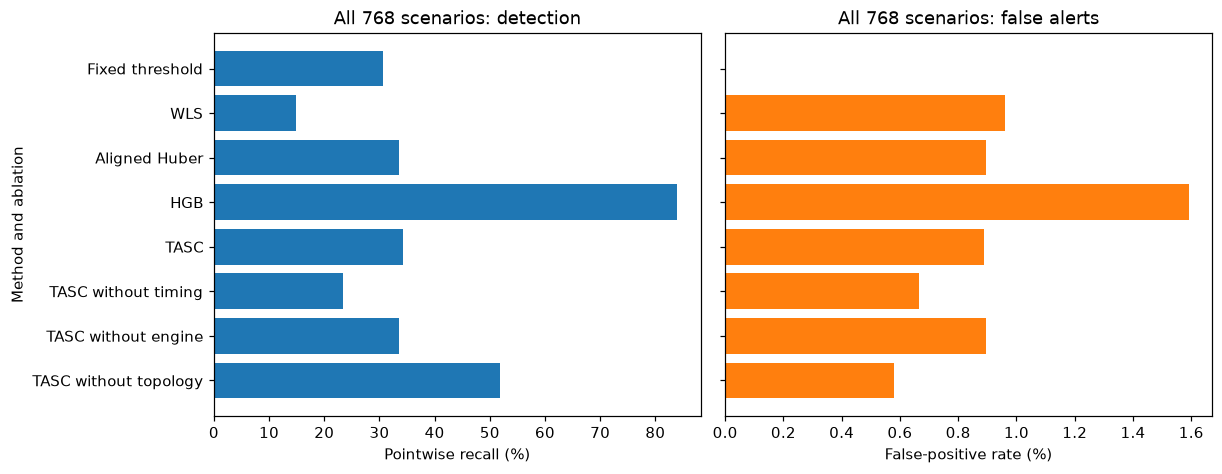

In [11]:
# Show the negative topology result alongside all reported alternatives.
labels = ["Fixed threshold", "WLS", "Aligned Huber", "HGB", "TASC",
          "TASC without timing", "TASC without engine", "TASC without topology"]
positions = np.arange(len(method_order))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), layout="constrained", sharey=True)
axes[0].barh(positions, [100 * aggregate[m]["recall"] for m in method_order])
axes[1].barh(positions, [100 * aggregate[m]["fpr"] for m in method_order], color="tab:orange")
axes[0].set_yticks(positions, labels)
axes[0].invert_yaxis()
axes[0].set(title="All 768 scenarios: detection", xlabel="Pointwise recall (%)", ylabel="Method and ablation")
axes[1].set(title="All 768 scenarios: false alerts", xlabel="False-positive rate (%)")
plt.show()

TASC barely improves recall over aligned Huber, remains far below the predictor, and loses to its own
no-topology ablation on both recall and false-positive rate. The no-engine result coincides with aligned
Huber, as intended by the construction. Timing removal lowers recall as well as false alerts, which is a
tradeoff rather than a one-dimensional verdict. The matched source-valid subset preserves the unfavorable
recall ordering, so the negative topology finding cannot be dismissed solely as a missing-data artifact.

Plot paired recall differences with their seed-block intervals next. The comparison with the predictor has
broader uncertainty because performance varies across held-out seeded loads. The narrow negative interval
against no-topology is still only evidence about this authored process and fixed prior. More seeds cannot
transform a misspecified experiment into field validation; the next methodological decision would be to
revise the assumptions and preregister a new held-out evaluation.

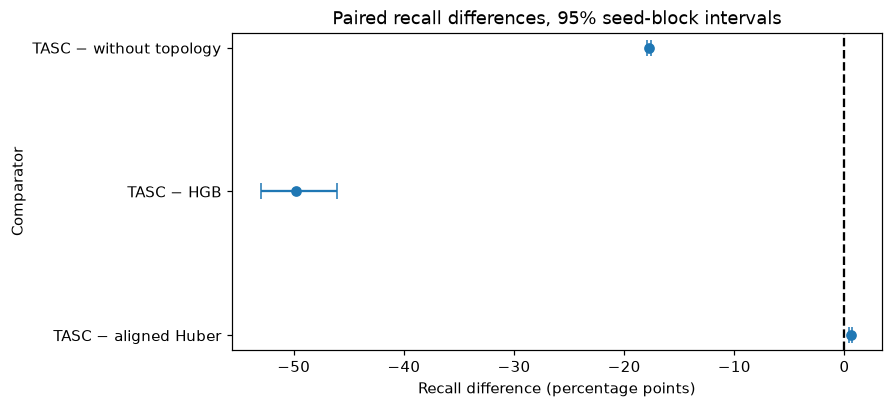

Aligned Huber: 0.0056875; interval=[0.004375  0.0070938]
HGB: -0.4980312; interval=[-0.5293133 -0.4610281]
TASC without topology: -0.1771875; interval=[-0.1792188 -0.1752812]


In [12]:
# Use paired seed blocks rather than independent channel-time draws for uncertainty.
differences = [r for r in analysis["paired_differences"] if r["metric"] == "recall"]
point = np.array([r["difference"] for r in differences]) * 100
limits = np.array([r["ci95"] for r in differences]) * 100
errors = np.vstack([point - limits[:, 0], limits[:, 1] - point])
fig, axis = plt.subplots(figsize=(8, 3.6), layout="constrained")
axis.errorbar(point, np.arange(3), xerr=errors, fmt="o", capsize=5)
axis.axvline(0, color="black", linestyle="--")
axis.set_yticks(np.arange(3), ["TASC − aligned Huber", "TASC − HGB", "TASC − without topology"])
axis.set(title="Paired recall differences, 95% seed-block intervals",
         xlabel="Recall difference (percentage points)", ylabel="Comparator")
plt.show()
for row in differences:
    print(f"{method_labels[row['reference']]}: {row['difference']:.7f}; "
          f"interval={np.round(row['ci95'], 7)}")

The intervals do not cross zero for the recall comparisons shown: the gain over aligned Huber is small,
while the losses to the predictor and no-topology variant are large in this matrix. This is evidence
against a general superiority claim for the proposed fusion. It does not determine which component should
be removed in a real plant, where instrumentation, storage, topology and compatible engine uncertainty
would need independent measurement. The experiment's ability to retain this unfavorable conclusion is
part of its usefulness as a reproducible research object.

## Results

**Answer:** The selected admitted flotation factor has a 104.802367 t/h innovation, or 10.424566 σ, but two
different ten-t/h fault hypotheses share the same balance syndrome. Missing covered dry-solids data allow
a separate estimate with a NaN observation score; missing uncovered water data return an unobservable state.
Across 6144 method/scenario cells, TASC recall is 34.190625%, versus 33.621875% for aligned Huber, 83.993750%
for HGB and 51.909375% without topology. The paired recall difference from no-topology is -0.1771875, with
95% interval [-0.1792188, -0.1752812]. These results do not support reliable general localization or superiority.

TASC has 256000 unscorable numerical entries in the full matrix; its delay negative control produces 3532
false alarms and null recall because no sensor fault exists. The three-case fresh execution above also
preserves its local missing-case 800 unscorable entries. Report those support limits with the attractive
factor explanation. Quality rejection, a numerical state estimate, a process alarm and a causal diagnosis
remain separate statements.

## Summary

TASC supplies a specific robust fusion and local provenance mechanism, but its constraints do not remove
ambiguity and its current evidence is negative on important comparisons. We exercised its actual acceptance
boundary, ran its ablations, and recomputed seed-paired uncertainty without discarding nulls or refusals.
A future plant study needs measured timing, inventory and model compatibility, plus held-out performance
that survives the same transparent treatment of failure.

## References

- Huber (1964), robust loss: https://doi.org/10.1214/aoms/1177703732
- Sadeghi, Hodouin and Bazin (2018), mineral reconciliation: https://doi.org/10.1016/j.mineng.2018.04.023
- scikit-learn, maintained histogram boosting estimator: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingRegressor.html
- Deng and Hooi (2021), sensor-relation prior work, not an executed GDN comparison: https://arxiv.org/abs/2106.06947
- Executed TASC: `data-pipeline/pipeline/model/reconciliation.py`; exact benchmark score-support rules:
  `data-pipeline/pipeline/stages/plant_evaluate.py`; paired resampling: `data-pipeline/pipeline/stages/analysis.py`.
- Frozen inputs: `data/derived/benchmark.json`, `data/derived/benchmark-analysis.json`; method assumptions:
  `docs/problem-types/02_state-coherence-experiment.md` and `docs/design/SDD.md`.